In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('Uber Request Data.csv')

In [3]:
df.head(10)

,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp
0,619,Airport,1.0,Trip Completed,11-07-16 11:51:00,11-07-16 13:00:00
1,867,Airport,1.0,Trip Completed,11-07-16 17:57:00,11-07-16 18:47:00
2,1807,City,1.0,Trip Completed,12-07-16 09:17:00,12-07-16 09:58:00
3,2532,Airport,1.0,Trip Completed,12-07-16 21:08:00,12-07-16 22:03:00
4,3112,City,1.0,Trip Completed,13-07-2016 08:33:16,13-07-2016 09:25:47
5,3879,Airport,1.0,Trip Completed,13-07-2016 21:57:28,13-07-2016 22:28:59
6,4270,Airport,1.0,Trip Completed,14-07-2016 06:15:32,14-07-2016 07:13:15
7,5510,Airport,1.0,Trip Completed,15-07-2016 05:11:52,15-07-2016 06:07:52
8,6248,City,1.0,Trip Completed,15-07-2016 17:57:27,15-07-2016 18:50:51
9,267,City,2.0,Trip Completed,11-07-16 06:46:00,11-07-16 07:25:00


In [4]:
df.describe()

,Request id,Driver id
count,6745.000000,4095.000000
mean,3384.644922,149.501343
std,1955.099667,86.051994
min,1.000000,1.000000
25%,1691.000000,75.000000
50%,3387.000000,149.000000
75%,5080.000000,224.000000
max,6766.000000,300.000000


In [5]:
df.count

<bound method DataFrame.count of       Request id Pickup point  Driver id             Status  \
0            619      Airport        1.0     Trip Completed   
1            867      Airport        1.0     Trip Completed   
2           1807         City        1.0     Trip Completed   
3           2532      Airport        1.0     Trip Completed   
4           3112         City        1.0     Trip Completed   
...          ...          ...        ...                ...   
6740        6745         City        NaN  No Cars Available   
6741        6752      Airport        NaN  No Cars Available   
6742        6751         City        NaN  No Cars Available   
6743        6754         City        NaN  No Cars Available   
6744        6753      Airport        NaN  No Cars Available   

        Request timestamp       Drop timestamp  
0       11-07-16 11:51:00    11-07-16 13:00:00  
1       11-07-16 17:57:00    11-07-16 18:47:00  
2       12-07-16 09:17:00    12-07-16 09:58:00  
3       12-07-16 21:08:00    12-07-16 22:03:00  
4     13-07-2016 08:33:16  13-07-2016 09:25:47  
...                   ...                  ...  
6740  15-07-2016 23:49:03                  NaN  
6741  15-07-2016 23:50:05                  NaN  
6742  15-07-2016 23:52:06                  NaN  
6743  15-07-2016 23:54:39                  NaN  
6744  15-07-2016 23:55:03                  NaN  

[6745 rows x 6 columns]>

In [6]:
df.isnull().sum()

,0
Request id,0
Pickup point,0
Driver id,2650
Status,0
Request timestamp,0
Drop timestamp,3914


In [7]:
df['Drop timestamp']=pd.to_datetime(df['Drop timestamp'], dayfirst=True,errors='coerce')
df['Request timestamp']=pd.to_datetime(df['Request timestamp'], dayfirst=True, errors='coerce')

/tmp/ipython-input-7-3747212872.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Drop timestamp']=pd.to_datetime(df['Drop timestamp'], dayfirst=True,errors='coerce')
/tmp/ipython-input-7-3747212872.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Request timestamp']=pd.to_datetime(df['Request timestamp'], dayfirst=True, errors='coerce')


In [8]:
df['Request Hour']=df['Request timestamp'].dt.hour
df['Request Day']=df['Request timestamp'].dt.day_name()


In [9]:
df.head()

,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp,Request Hour,Request Day
0,619,Airport,1.0,Trip Completed,2016-07-11 11:51:00,2016-07-11 13:00:00,11,Monday
1,867,Airport,1.0,Trip Completed,2016-07-11 17:57:00,2016-07-11 18:47:00,17,Monday
2,1807,City,1.0,Trip Completed,2016-07-12 09:17:00,2016-07-12 09:58:00,9,Tuesday
3,2532,Airport,1.0,Trip Completed,2016-07-12 21:08:00,2016-07-12 22:03:00,21,Tuesday
4,3112,City,1.0,Trip Completed,2016-07-13 08:33:16,2016-07-13 09:25:47,8,Wednesday


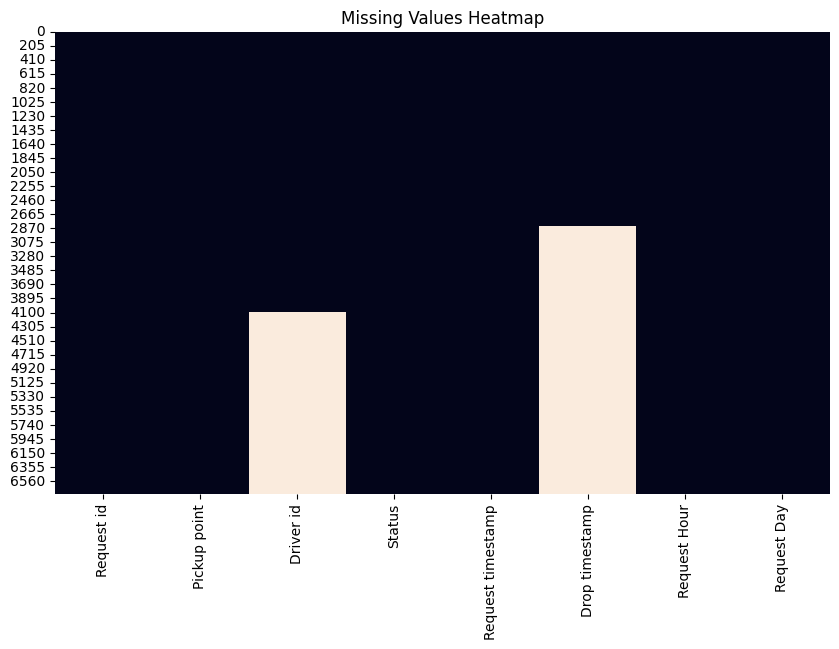

In [10]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(),cbar=False)
plt.title('Missing Values Heatmap')
plt.show()

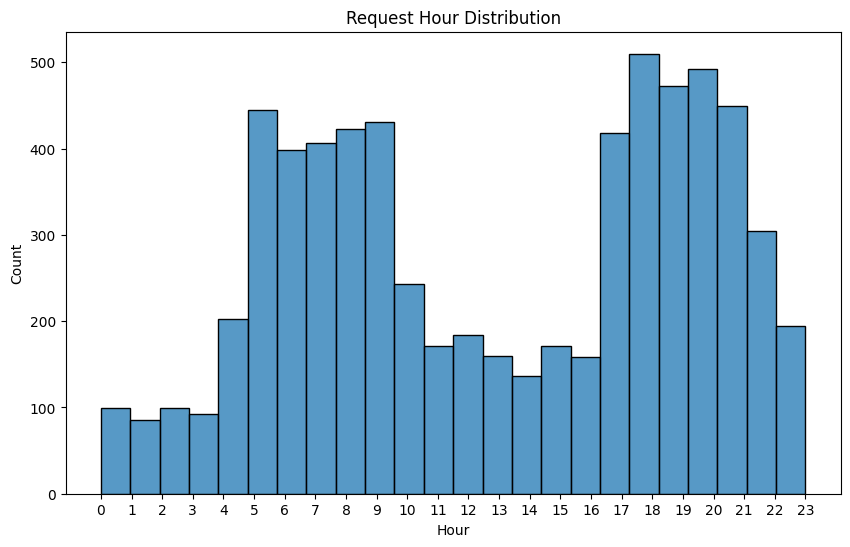

In [11]:
plt.figure(figsize=(10,6))
sns.histplot(df['Request Hour'],bins=24)
plt.title('Request Hour Distribution')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.xticks(range(0,24))
plt.show()

<Axes: xlabel='Request Day', ylabel='count'>

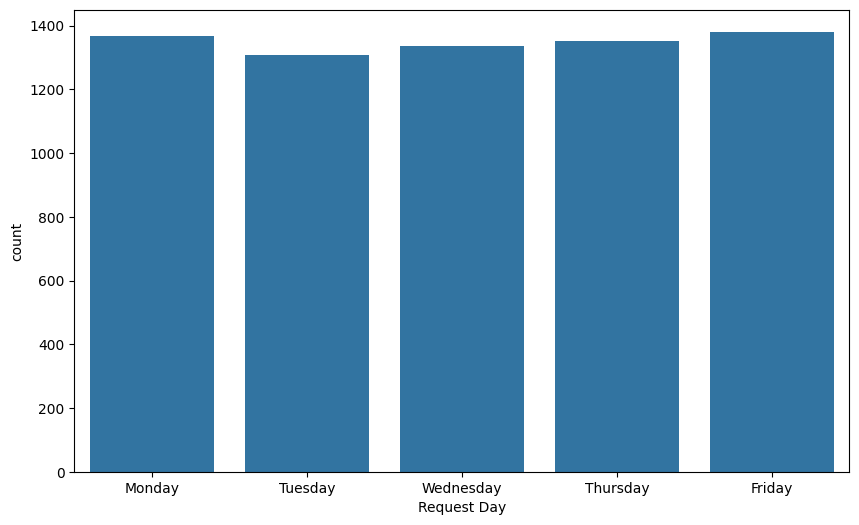

In [12]:
plt.figure(figsize=(10,6))
sns.countplot(data=df,x='Request Day')

<Axes: xlabel='Pickup point', ylabel='count'>

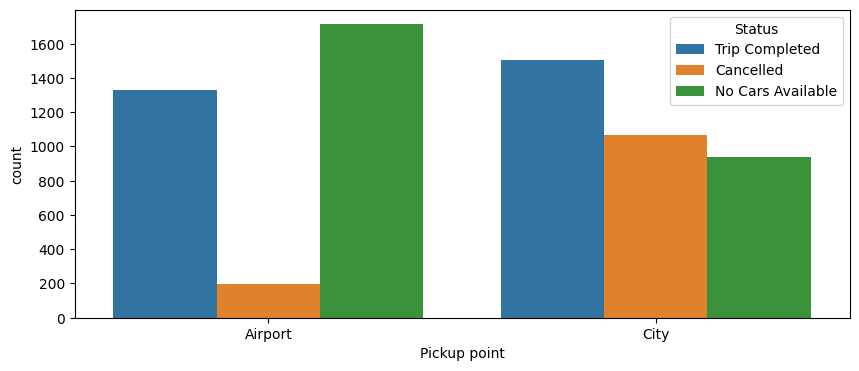

In [13]:
plt.figure(figsize=(10,4))
sns.countplot(data=df,x='Pickup point',hue='Status')

In [14]:
df

,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp,Request Hour,Request Day
0,619,Airport,1.0,Trip Completed,2016-07-11 11:51:00,2016-07-11 13:00:00,11,Monday
1,867,Airport,1.0,Trip Completed,2016-07-11 17:57:00,2016-07-11 18:47:00,17,Monday
2,1807,City,1.0,Trip Completed,2016-07-12 09:17:00,2016-07-12 09:58:00,9,Tuesday
3,2532,Airport,1.0,Trip Completed,2016-07-12 21:08:00,2016-07-12 22:03:00,21,Tuesday
4,3112,City,1.0,Trip Completed,2016-07-13 08:33:16,2016-07-13 09:25:47,8,Wednesday
...,...,...,...,...,...,...,...,...
6740,6745,City,NaN,No Cars Available,2016-07-15 23:49:03,NaT,23,Friday
6741,6752,Airport,NaN,No Cars Available,2016-07-15 23:50:05,NaT,23,Friday
6742,6751,City,NaN,No Cars Available,2016-07-15 23:52:06,NaT,23,Friday
6743,6754,City,NaN,No Cars Available,2016-07-15 23:54:39,NaT,23,Friday


In [16]:
df.to_csv('uber_request_data_updated.csv',index=False)